# Balance the APTOS  training data with augmentation



## 1. Imports and paths

In [ ]:
from pathlib import Path
import random
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Use the same seed and split order as the CLAHE CNN notebook. to maintain balance
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

PROJECT_ROOT = Path.cwd()
DATASET_DIR = PROJECT_ROOT / "datasets" / "preprocessed_aptos_512_clahe"
OUTPUT_DIR = PROJECT_ROOT / "datasets" / "aptos_512_clahe_balanced"
TRAIN_DIR = OUTPUT_DIR / "train"
VAL_DIR = OUTPUT_DIR / "validation"
TEST_DIR = OUTPUT_DIR / "test"
TRAIN_IMAGES_DIR = TRAIN_DIR / "images"
VAL_IMAGES_DIR = VAL_DIR / "images"
TEST_IMAGES_DIR = TEST_DIR / "images"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
VAL_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
TEST_IMAGES_DIR.mkdir(parents=True, exist_ok=True)
NUM_CLASSES = 5


## 2. Load labels and inspect the starting counts

In [ ]:
#Read labels from the preprocessed  training set.
labels = pd.read_csv(DATASET_DIR / "train.csv")
print("Original class counts:")
print(labels["diagnosis"].value_counts().sort_index())


Original class counts:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


## augment only training data

In [ ]:
#we split the folders here automatically so we dont need to apply the train test split percentages in our models just access the folder it made

#Keep a held-out test split and validation split separate from training.
train_val, test_df = train_test_split(
    labels, test_size=0.15, random_state=SEED,
    stratify=labels["diagnosis"]
)
train_df, val_df = train_test_split(
    train_val, test_size=(0.15 / 0.85), random_state=SEED,
    stratify=train_val["diagnosis"]
)

print(f"Training: {len(train_df)} ({len(train_df) / len(labels):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df) / len(labels):.1%})")
print(f"Test: {len(test_df)} ({len(test_df) / len(labels):.1%})")
print("Training class counts before augmentation:")
print(train_df["diagnosis"].value_counts().sort_index())


Training: 2562 (70.0%)
Validation: 550 (15.0%)
Test: 550 (15.0%)
Training class counts before augmentation:
diagnosis
0    1263
1     258
2     699
3     135
4     207
Name: count, dtype: int64


## 4. Set up image augmentation

In [4]:
# Random transformations make new training examples while preserving the diagnosis.
# Grade 0 images are never passed through this augmenter.
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, fill_mode="constant", seed=SEED),
    tf.keras.layers.RandomZoom(0.08, fill_mode="constant", seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
])

# Load a CLAHE PNG, apply one random transformation, and save a new PNG.
def create_augmented_image(source_path, output_path):
    image_bytes = tf.io.read_file(str(source_path))
    image = tf.io.decode_png(image_bytes, channels=3)
    image = tf.cast(image, tf.float32)
    augmented = augmenter(tf.expand_dims(image, axis=0), training=True)[0]
    augmented = tf.clip_by_value(augmented, 0, 255)
    augmented = tf.cast(augmented, tf.uint8)
    tf.io.write_file(str(output_path), tf.io.encode_png(augmented))


## 5. Create a balanced class training set

In [ ]:
#alance only the training split to the number of grade 0 training examples.(1200)
#Copy original images into their split folders; generated images are added only to train.
target_count = int((train_df["diagnosis"] == 0).sum())
training_rows = []

for row in train_df.itertuples(index=False):
    source_path = DATASET_DIR / "train_images" / f"{row.id_code}.png"
    shutil.copy2(source_path, TRAIN_IMAGES_DIR / f"{row.id_code}.png")
    training_rows.append({
        "id_code": str(row.id_code),
        "diagnosis": int(row.diagnosis),
        "is_augmented": False,
    })

# Copy validation and test images without changing them or augmenting them.
for row in val_df.itertuples(index=False):
    source_path = DATASET_DIR / "train_images" / f"{row.id_code}.png"
    shutil.copy2(source_path, VAL_IMAGES_DIR / f"{row.id_code}.png")
for row in test_df.itertuples(index=False):
    source_path = DATASET_DIR / "train_images" / f"{row.id_code}.png"
    shutil.copy2(source_path, TEST_IMAGES_DIR / f"{row.id_code}.png")

#For grades 1–4, create enough random variants to match grade 0's training count.
for grade in range(1, NUM_CLASSES):
    grade_rows = train_df[train_df["diagnosis"] == grade]
    missing_count = target_count - len(grade_rows)
    sampled_rows = grade_rows.sample(
        n=missing_count, replace=True, random_state=SEED + grade
    )

    for number, row in enumerate(sampled_rows.itertuples(index=False), start=1):
        new_id = f"aug_grade{grade}_{number:05d}"
        output_path = TRAIN_IMAGES_DIR / f"{new_id}.png"
        source_path = DATASET_DIR / "train_images" / f"{row.id_code}.png"
        create_augmented_image(source_path, output_path)
        training_rows.append({
            "id_code": new_id,
            "diagnosis": grade,
            "is_augmented": True,
        })
    print(f"Grade {grade}: created {missing_count} augmented images")

balanced_train = pd.DataFrame(training_rows)
balanced_train.to_csv(TRAIN_DIR / "labels.csv", index=False)
val_df[["id_code", "diagnosis"]].to_csv(VAL_DIR / "labels.csv", index=False)
test_df[["id_code", "diagnosis"]].to_csv(TEST_DIR / "labels.csv", index=False)

print("\nBalanced training counts:")
print(balanced_train["diagnosis"].value_counts().sort_index())
print("\nSaved split folders to:", OUTPUT_DIR.resolve())


Grade 1: created 1005 augmented images
Grade 2: created 564 augmented images
Grade 3: created 1128 augmented images
Grade 4: created 1056 augmented images

Balanced training counts:
diagnosis
0    1263
1    1263
2    1263
3    1263
4    1263
Name: count, dtype: int64

Saved split folders to: D:\omar\SIC\grad_project\datasets\aptos_512_clahe_balanced


## 6. Preview and verify grade 0 didnt increase 

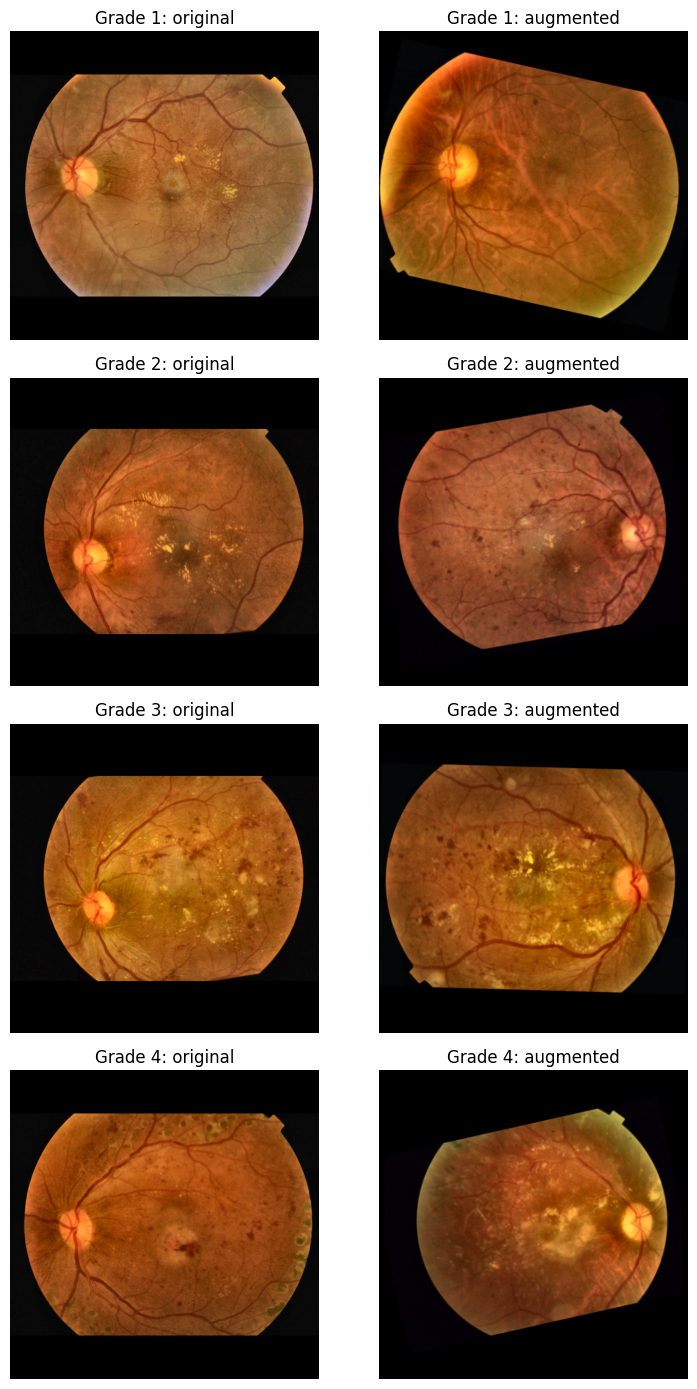

Grade 0 rows: 1263
Augmented grade 0 rows: 0


In [6]:
# Show one original and one generated example from each augmented grade.
fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for row_index, grade in enumerate(range(1, NUM_CLASSES)):
    original_row = train_df[train_df["diagnosis"] == grade].iloc[0]
    generated_row = balanced_train[
        (balanced_train["diagnosis"] == grade) & balanced_train["is_augmented"]
    ].iloc[0]

    original_image = plt.imread(PROJECT_ROOT / "datasets" / "preprocessed_aptos_512_clahe" / "train_images" / f"{original_row['id_code']}.png")
    augmented_image = plt.imread(TRAIN_IMAGES_DIR / f"{generated_row['id_code']}.png")
    axes[row_index, 0].imshow(original_image)
    axes[row_index, 0].set_title(f"Grade {grade}: original")
    axes[row_index, 1].imshow(augmented_image)
    axes[row_index, 1].set_title(f"Grade {grade}: augmented")
    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "augmentation_preview.png", dpi=200, bbox_inches="tight")
plt.show()

# Grade 0 has original rows only; no generated grade 0 examples are present.
print("Grade 0 rows:", int((balanced_train["diagnosis"] == 0).sum()))
print("Augmented grade 0 rows:", int(((balanced_train["diagnosis"] == 0) & balanced_train["is_augmented"]).sum()))
